In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings 

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import r2_score, mean_absolute_error , mean_squared_error


In [2]:
df = pd.read_csv('/kaggle/input/datasets/mirichoi0218/insurance/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
def basic_analysis(df): 
    print("Column Names")
    print(df.columns.tolist())

    print("\n Data types and non null counts")
    df.info()

    print("\nMissing values per column:")
    display(df.isnull().sum())

    print("\nDuplicate rows:",df.duplicated().sum())

    print("\nnUnique values per column")
    display(df.nunique())

In [4]:
basic_analysis(df)

Column Names
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

 Data types and non null counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values per column:


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Duplicate rows: 1

nUnique values per column


age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64

In [5]:
num_cols = df.select_dtypes(include = ['int64', 'float64'])
num_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


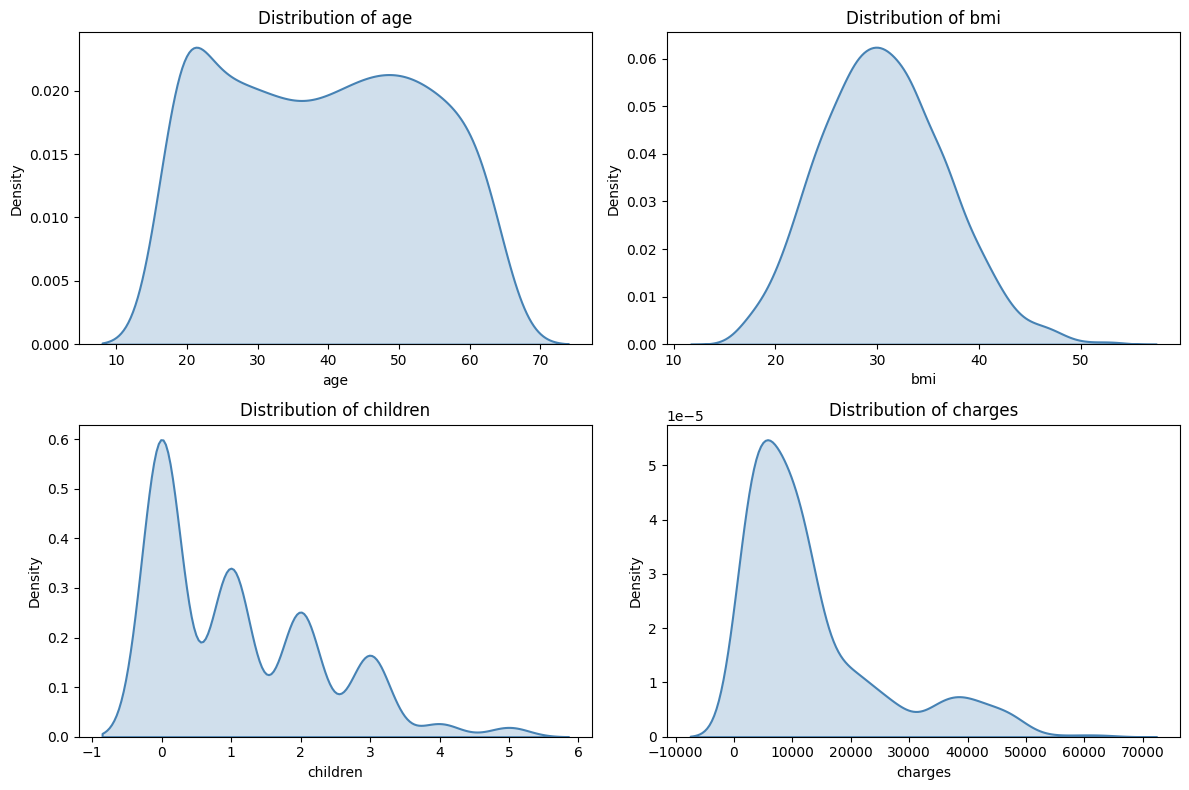

In [6]:

cols = num_cols.columns

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, cols):
    sns.kdeplot(
        data=df,
        x=col,
        color='steelblue',
        fill = True,
        linewidth=1.5,
        ax=ax
    )
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

Observations :->

1. Charges distribution is right skewed.
2. BMI distribution is normal but some extreme values could be seen.
3. Children distribution is non-continous distribution.
4. Age distribution is uniform.

Lets try some different approach here, we will build our model first and then try to fix our model step by step 

In [7]:
# Basic preprocessing:

le = LabelEncoder() 
df['sex'] = le.fit_transform(df['sex'])
df['smoker'] = le.fit_transform(df['smoker'])
df['region'] = le.fit_transform(df['region'])


In [8]:
def create_sets(df):
    X = df.drop(columns = ['charges', 'charges_log'])
    y = df.iloc[:,-1]

    X_train , X_test , y_train , y_test = train_test_split(X,y,test_size =0.2, random_state = 42)
    return X_train , X_test , y_train , y_test

In [9]:
def build_model(X_train,y_train,X_test):
    lr = LinearRegression() 
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    return y_pred

In [10]:
def calculate_model_score(y_pred,y_test): 
    print("Mean Squared Error: ", mean_squared_error(y_pred, y_test))
    print("Mean Absolute Error: ", mean_absolute_error(y_pred,y_test))
    print("R2 Score:",r2_score(y_pred, y_test))

In [11]:
# residuals = y_test - y_pred

# plt.figure(figsize=(8,6))

# sns.scatterplot(x=y_pred, y=residuals)

# plt.axhline(0, color='red')

# plt.xlabel("Predicted Charges")
# plt.ylabel("Residuals")
# plt.title("Residual Plot")

# plt.show()

In [12]:
# sns.scatterplot(
#     x=y_pred,
#     y=y_test-y_pred,
#     hue=X_test['smoker']
# )

# plt.axhline(0,color='red')
# plt.show()

The residual plot shows that the residuals are generally centered around zero, so , our model captures overall relationship between predictors and insurance charges. However in the graph we can see some distinguished pattern around predicted charges of 25000-40000. This is due the fact that charges differ across the sub groups smoker and non smoker as depicted by the orange colour in above graph.

We still have some room for improvement through feature engineering and preprocessing. 

We noticed our charges variable is right skewed. This is also affecting our model. 

In [13]:
df['charges_log'] = np.log(df['charges'])
df['charges_log']

0        9.734176
1        7.453302
2        8.400538
3        9.998092
4        8.260197
          ...    
1333     9.268661
1334     7.698927
1335     7.396233
1336     7.604867
1337    10.279914
Name: charges_log, Length: 1338, dtype: float64

In [14]:
sets = create_sets(df)
y_pred = build_model(sets[0],sets[2],sets[1])
calculate_model_score(y_pred, sets[3])

Mean Squared Error:  0.17756248562721857
Mean Absolute Error:  0.27082052110955845
R2 Score: 0.7415242119670591


Our R2 Score improved further from 0.70 to 0.74

In [15]:
df

,age,sex,bmi,children,smoker,region,charges,charges_log
0,19,0,27.900,0,1,3,16884.92400,9.734176
1,18,1,33.770,1,0,2,1725.55230,7.453302
2,28,1,33.000,3,0,2,4449.46200,8.400538
3,33,1,22.705,0,0,1,21984.47061,9.998092
4,32,1,28.880,0,0,1,3866.85520,8.260197
...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,10600.54830,9.268661
1334,18,0,31.920,0,0,0,2205.98080,7.698927
1335,18,0,36.850,0,0,2,1629.83350,7.396233
1336,21,0,25.800,0,0,3,2007.94500,7.604867
